In [1]:
import numpy as np
import sys
import os
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display

In [2]:
sys.path.append(os.path.abspath(os.path.join(".", "..")))
import bssneqs as bssn
import bssnutils as butil
import tomllib
from nwave import *

In [3]:
def cal_func(x, mode1, mode2, amp):
    #f = np.empty_like(x)
    #df = np.empty_like(x)
    #ddf = np.empty_like(x)
    L = x[-1] - x[0]
    k1 = mode1*np.pi/L
    k2 = mode2*np.pi/L

    f = amp * (np.sin(k1*x) + np.cos(k2*x))
    df = amp * (k1*np.cos(k1*x) - k2*np.sin(k2*x))
    ddf = amp*(-k1*k1*np.sin(k1*x) - k2*k2*np.cos(k2*x))
    return f, df, ddf

def l2norm(f,imask=0):
    # Sum the squares of each element
    if imask == 0:
        seg = f
    else:
        seg = f[imask:-imask]
        
    s = np.dot(seg, seg)
    return np.sqrt(s/(len(seg)-1))

def cal_self_convergence(f4h, f2h, fh, imask=0):
    f4 = f4h
    f2 = f2h[::2]
    f1 = fh[::4]
    #f4 = f4x[imask:-imask)]
    #f2 = f2x[imask:-imask)]
    #f1 = f1x[imask:-imask)]

    if len(f4) != len(f2) != len(f1):
        print(f"array sizes not equal.  {len(f4)}, {len(f2)}, {len(f1)}")
        return 0
    d2 = f2 - f1
    d4 = f4 - f2
    cf = np.log(l2norm(d4,imask)/l2norm(d2,imask))/np.log(2.0)
    return [d4, d2, cf]

In [70]:
def cal_derivs(x, mass):
    d_alpha = np.empty_like(x)
    dd_alpha = np.empty_like(x)
    d_Gt = np.empty_like(x)

    for i in range(len(x)):
        if x[i] < 0:
            d_Gt[i] = -2.0/x[i]**2
            d_alpha[i] = 8.0*mass*x[i]/(mass - 2.0*x[i])**3
            dd_alpha[i] = 8.0*mass*(mass + 4.0*x[i])/(mass - 2.0*x[i])**4
        else:
            d_Gt[i] = 2.0/x[i]**2
            d_alpha[i] = 8.0*mass*x[i]/(mass + 2.0*x[i])**3
            dd_alpha[i] = 8.0*mass*(mass - 4.0*x[i])/(mass + 2.0*x[i])**4

    return d_alpha, dd_alpha, d_Gt

def run_tests(params, nxbase, level):
    cellgrid = False
    params["NGhost"] = 0
    params["Xmin"] = -1.0
    params["Xmax"] = 1.0

    if nxbase % 2 == 1:
        nxbase -= 1
    nx0 = 2**level*nxbase + 1
    params["Nx"] = nx0
    g = Grid1D(params, cell_centered=cellgrid)
    r = g.xi[0]

    D1, D2 = butil.init_derivative_operators(r, params)
    g.set_D1(D1)
    g.set_D2(D2)
    print(f"D1 type: {g.D1.get_type()}")

    amp = 1.0
    mode1 = 7.0
    mode2 = 11.0
    f, edf, eddf = cal_func(r, mode1, mode2, amp)
    
    df = D1.grad(f)
    ddf = D2.grad(f)
    return [r, f, edf, eddf, df, ddf]
    

def run_BHtests(params, level):
    cellgrid = False
    params["collapsed_lapse"] = True
    params["NGhost"] = 0
    mass = params["Mass"]
    extended_domain = True

    nx = params["Nx"]
    if nx % 2 == 1:
        nx -= 1
    nx0 = 2**level*nx + 1
    params["Nx"] = nx0
    g = Grid1D(params, cell_centered=cellgrid)
    r = g.xi[0]
    
    D1, D2 = butil.init_derivative_operators(r, params)
    g.set_D1(D1)
    g.set_D2(D2)
    print(f"D1 type: {g.D1.get_type()}")

    # GBSSN system: (sys, lapse advection, shift advection)
    #    sys = 0 (Eulerian), 1 (Lagrangian)
    sys = bssn.GBSSNSystem(1, 1, 1)
    eqs = bssn.BSSN(g, params["Mass"], params["eta"], extended_domain, "FUNCTION", sys, have_d2=True)
    eqs.initialize(g, params)
    alpha = eqs.u[eqs.U_ALPHA]
    Gt = eqs.u[eqs.U_GT]
    d_alpha = D1.grad(alpha)
    d2_alpha = D2.grad(alpha)
    d_Gt = D1.grad(Gt)
    ed_alpha, edd_alpha, ed_Gt = cal_derivs(x, mass)
    
    return [r, alpha, Gt, d_alpha, ed_alpha, edd_alpha, ed_Gt, d_alpha, dd_alpha, d_Gt]
    
    

In [81]:
inputstring = """
# This is a sample input file for the BSSN code.
Nt = 12
Nx =  100
Xmin =-10.0
Xmax = 10.0
level = 0

NGhost = 0
cfl = 0.15
eta = 2.0

D1 = ["ME4"]
D2 = ["ME4"]
DerivSolveMethod = "SCIPY"

BHMask = true
BHMaskPos = 0.0
BHMaskWidth = 0.1

Filter = "F2"
FilterKOsigma = 0.5
FilterBoundary = true
FilterApply = "Vars"
FilterFrequency = 10
FilterAlpha = 0.4

# initial data types = [ "Puncture", "EddingtonFinkelstein" ]
Mass = 1.0
collapsed_lapse = false
initial_data = "Puncture"

# output parameters
output_dir = "output_bssn"
output_interval = 50
print_interval = 5
"""
params = tomllib.loads(inputstring)

In [126]:
levels = [0, 1, 2]
nxbase = 50

params["D1"] = ["JP6", "ME6"]
params["D2"] = ["JP6", "ME6"]

params["BHMask"] = True
params["BHMaskPos"] = 0.0
params["BHMaskWidth"] = 0.3

xlist = []
flist = []
dlist = []
elist = []
e2list = []
d2list = []

for level in levels:
    d1 = run_tests(params, nxbase, level)
    xlist.append(d1[0])
    flist.append(d1[1])
    elist.append(d1[2])
    e2list.append(d1[3])
    dlist.append(d1[4])
    d2list.append(d1[5])
    

Grid1D: nx=51, xmin=-1.0, xmax=1.0, dx=0.04, ng=0 cell_centered=False
init_derivative_operators>>  d1_param = ['JP6', 'ME6']
init_derivative_operators>>  d2_param = ['JP6', 'ME6']
init_derivative_operators>>  d1_list = ['JP6', 'ME6']
init_derivative_operators>>  mask_bh  = True
init_derivative_operators>> Setting BH Masked derivative for D1. Background type: DerivType.D1_JP6, BH type: DerivType.D1_ME642
init_derivative_operators>> BH Mask. position: 0.0, width: 0.3
init_derivative_operators>> Setting BH Masked derivative for D2. Background type: DerivType.D2_JP6, BH type: DerivType.D2_ME642
D1 type: DerivType.D1_JP6
Grid1D: nx=101, xmin=-1.0, xmax=1.0, dx=0.02, ng=0 cell_centered=False
init_derivative_operators>>  d1_param = ['JP6', 'ME6']
init_derivative_operators>>  d2_param = ['JP6', 'ME6']
init_derivative_operators>>  d1_list = ['JP6', 'ME6']
init_derivative_operators>>  mask_bh  = True
init_derivative_operators>> Setting BH Masked derivative for D1. Background type: DerivType.D1_J

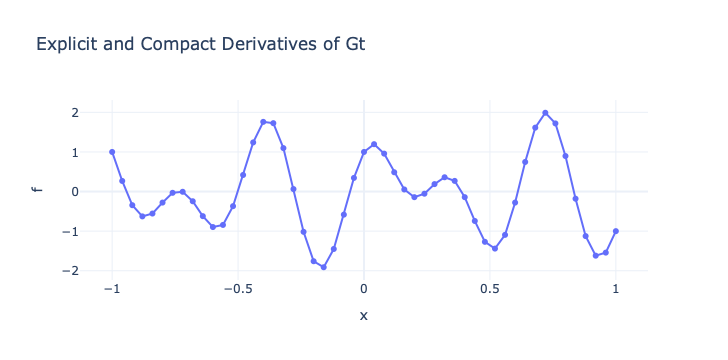

In [127]:
# our custom event handler
def update_trace(trace, points, selector):
    # this list stores the points which were clicked on
    # in all but one trace they are empty
    if len(points.point_inds) == 0:
        return          
    for i,_ in enumerate(fig.data):
        fig.data[i]['line']['width'] = default_linewidth + highlighted_linewidth_delta * (i == points.trace_index)

default_linewidth = 2
highlighted_linewidth_delta = 2

fig = go.Figure()
fig.add_trace(go.Scatter(x=xlist[0], y=flist[0], name="func", mode="lines+markers",hoverinfo='skip'))

# we need to add the on_click event to each trace separately       
for i in range( len(fig.data) ):
    fig.data[i].on_click(update_trace)

# Layout with log scale option
fig.update_layout(
    title='Explicit and Compact Derivatives of Gt',
    xaxis=dict(title='x', type='linear'),  # use 'log' for log scale
    yaxis=dict(title='f'),
    #xaxis_range=[0,1],
    #yaxis_range=[-2.5,2.5],
    hovermode='x',
    template='plotly_white'
)

fig.show()

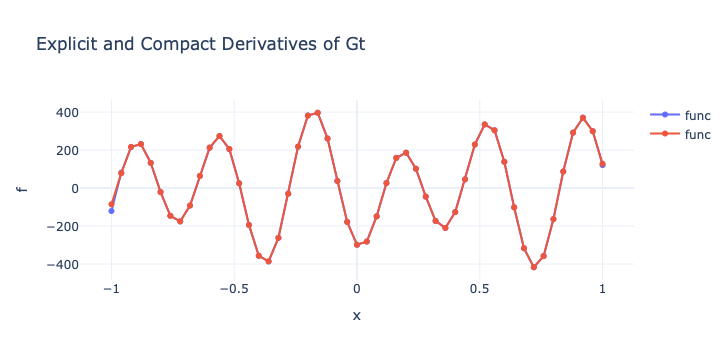

In [128]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=xlist[0], y=e2list[0], name="func", mode="lines+markers",hoverinfo='skip'))
fig.add_trace(go.Scatter(x=xlist[0], y=d2list[0], name="func", mode="lines+markers",hoverinfo='skip'))

# we need to add the on_click event to each trace separately       
for i in range( len(fig.data) ):
    fig.data[i].on_click(update_trace)

# Layout with log scale option
fig.update_layout(
    title='Explicit and Compact Derivatives of Gt',
    xaxis=dict(title='x', type='linear'),  # use 'log' for log scale
    yaxis=dict(title='f'),
    #xaxis_range=[0,1],
    #yaxis_range=[-50,50],
    hovermode='x',
    template='plotly_white'
)

fig.show()

In [129]:
derr = []
d2err = []

for ef, df in zip(elist, dlist):
    yy = df - ef
    derr.append(yy)

for ef, df in zip(e2list, d2list):
    yy = df - ef
    d2err.append(yy)

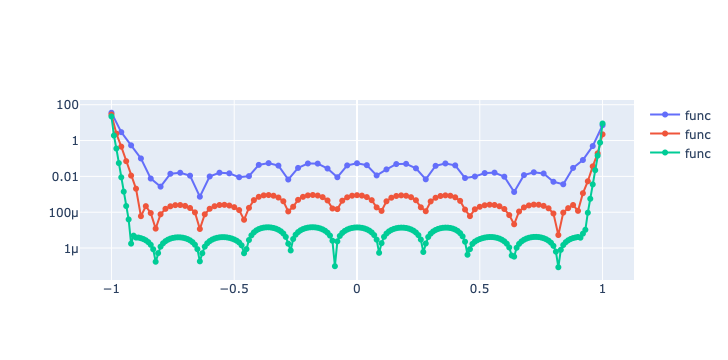

In [130]:
fig = go.Figure()
for x, f in zip(xlist, d2err):
    fig.add_trace(go.Scatter(x=x, y=np.abs(f), name="func", mode="lines+markers",hoverinfo='skip'))

fig.update_yaxes(type="log")   # <-- semilog-y
fig.show()

In [131]:
imask = 20
if (len(derr[0]) - 2*imask) < 2:
    imask = 0

d0nrm = l2norm(derr[0],imask)
d1nrm = l2norm(derr[1],imask)
d2nrm = l2norm(derr[2],imask)
dd0nrm = l2norm(d2err[0],imask)
dd1nrm = l2norm(d2err[1],imask)
dd2nrm = l2norm(d2err[2],imask)
dacf = np.log(d0nrm/d1nrm)/np.log(2.0)
dbcf = np.log(d1nrm/d2nrm)/np.log(2.0)

ddacf = np.log(dd0nrm/dd1nrm)/np.log(2.0)
ddbcf = np.log(dd1nrm/dd2nrm)/np.log(2.0)

print(f"First deriv level 0, 1: {d0nrm}, {d1nrm}, CF: {dacf}")
print(f"First deriv level 1, 2: {d1nrm}, {d2nrm}, CF: {dbcf}")
print(f"Second deriv level 0, 1: {dd0nrm}, {dd1nrm}, CF: {ddacf}")
print(f"Second deriv level 1, 2: {dd1nrm}, {dd2nrm}, CF: {ddbcf}")

First deriv level 0, 1: 0.008447797788696431, 0.00012128832666314554, CF: 6.122062691178857
First deriv level 1, 2: 0.00012128832666314554, 1.6727006037952225e-06, CF: 6.180117654512998
Second deriv level 0, 1: 0.0427062004124046, 0.0005548408594942704, CF: 6.266227702042771
Second deriv level 1, 2: 0.0005548408594942704, 7.734296840684861e-06, CF: 6.164660088230861


In [132]:
data1 = cal_self_convergence(dlist[0], dlist[1], dlist[2], imask)
print(f"convergence {data1[2]}")
data2 = cal_self_convergence(dlist[0], dlist[1], dlist[2], imask)
print(f"convergence {data2[2]}")

convergence 5.898248185356834
convergence 5.898248185356834


In [133]:
f = np.linspace(0,10,11)
f

array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])

In [15]:
f[0:-0]

array([], dtype=float64)

In [16]:
f[-1]

np.float64(10.0)